<a href="https://colab.research.google.com/github/DAustinGit/AqSolv/blob/feature%2Fuser_table/AqSolv%20/development%20notebooks/AqSolv_ensambles_extended_properties.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Further analysis of stacked training models

###load data from database

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split, learning_curve
df = pd.read_csv('solubility_training.csv')
y = df['measured log(solubility:mol/L)']   # Y is feature used for training
x = df.drop(['Compound_ID','measured log(solubility:mol/L)','SMILES'], axis=1)   #X is the feature we are predicting drop logS and axis = 1 --> work in coluns

x_train, x_test, y_train, y_test = train_test_split (x, y, test_size= 0.2, random_state = 100) #splits the data for train and test sets testing set is 20% of data
print (x_train)

      num_Rotatable_Bonds  num_H_Bond_Acceptors  num_H_Bond_Doners  \
149                     0                     1                  1   
641                     0                     1                  1   
201                     1                     0                  0   
1102                    0                     4                  0   
136                     1                     0                  0   
...                   ...                   ...                ...   
802                     1                     2                  0   
53                      3                     0                  0   
350                     0                     0                  0   
79                     10                     1                  1   
792                     3                     3                  2   

      num_Nitrogen_Oxygen  mol_weight     LogP  aromatic proportion    TPSA  
149                     1     231.893  4.00580             0.545455   20.23  
641

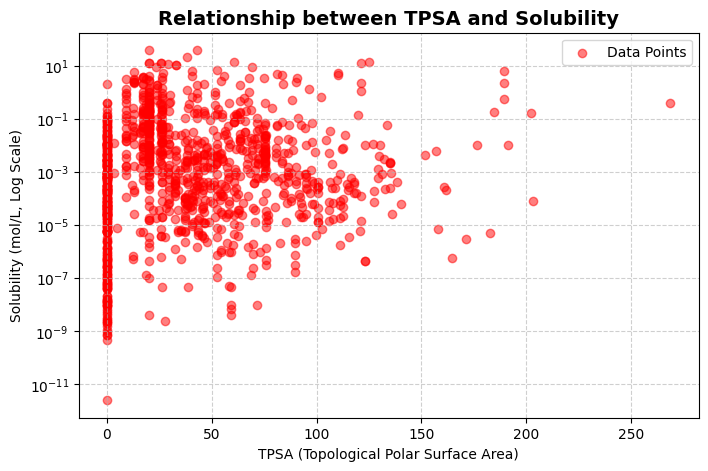

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

# Correctly calculate 10^x for actual solubility
actual_solubility = 10 ** df['measured log(solubility:mol/L)']

plt.scatter(df['TPSA'], actual_solubility, color="r", alpha=0.5, label="Data Points")

# Apply a log scale to the Y-axis to handle the wide range cleanly
plt.yscale('log')

# Formatting elements
plt.title("Relationship between TPSA and Solubility", fontsize=14, fontweight='bold')
plt.xlabel("TPSA (Topological Polar Surface Area)")
plt.ylabel("Solubility (mol/L, Log Scale)")
plt.grid(True, which="both", linestyle="--", alpha=0.6)
plt.legend()

plt.show()

##KNN BR RidgeCV Ensemble

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn import linear_model
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import StackingRegressor
from sklearn.model_selection import GridSearchCV

base_learners = [
    ('lr', linear_model.BayesianRidge()),
    ('knn', KNeighborsRegressor(weights='uniform',n_neighbors=12, algorithm='ball_tree', leaf_size=20))
]

stacking_ensemble = StackingRegressor(
    estimators=base_learners,
    final_estimator=RidgeCV(),
    cv = 2,

)

pipeline = Pipeline([
  ('scaler', StandardScaler()),
  ('stack', stacking_ensemble)
])


pipeline.fit(x_train, y_train)
y_train_pred = pipeline.predict(x_train)
y_test_pred = pipeline.predict(x_test)

# 6. Output the results
#print(f"Best Parameters: {grid_search.best_params_}")
#print(f"Best CV R² Score: {grid_search.best_score_:.4f}")
#print(f"Test Set R² Score: {grid_search.score(x_test, y_test):.4f}")

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
train_score = pipeline.score(x_train, y_train)
train_MSE = mean_squared_error(y_train, y_train_pred)
test_MSE = mean_squared_error(y_test, y_test_pred)
# 2. Calculate the score on the test data
test_score = pipeline.score(x_test, y_test)

print(f"Training R² Score: {train_score:.4f}")
print(f"Test R² Score:     {test_score:.4f}")

# 3. Evaluate the gap
gap = train_score - test_score
print(f"Performance Gap:   {gap:.4f}")

bkr_results = pd.DataFrame(['Baysian Ridge + KNN', 'RidgeCV', train_score, test_score, gap, test_MSE, train_MSE]).transpose()
bkr_results.columns = ['Base learners', 'final estimator', 'Training R2', 'testing R2', 'performance gap', 'test MSE', 'train MSE']
bkr_results

Training R² Score: 0.8795
Test R² Score:     0.8480
Performance Gap:   0.0314


,Base learners,final estimator,Training R2,testing R2,performance gap,test MSE,train MSE
0,Baysian Ridge + KNN,RidgeCV,0.879451,0.848045,0.031406,0.62797,0.531253


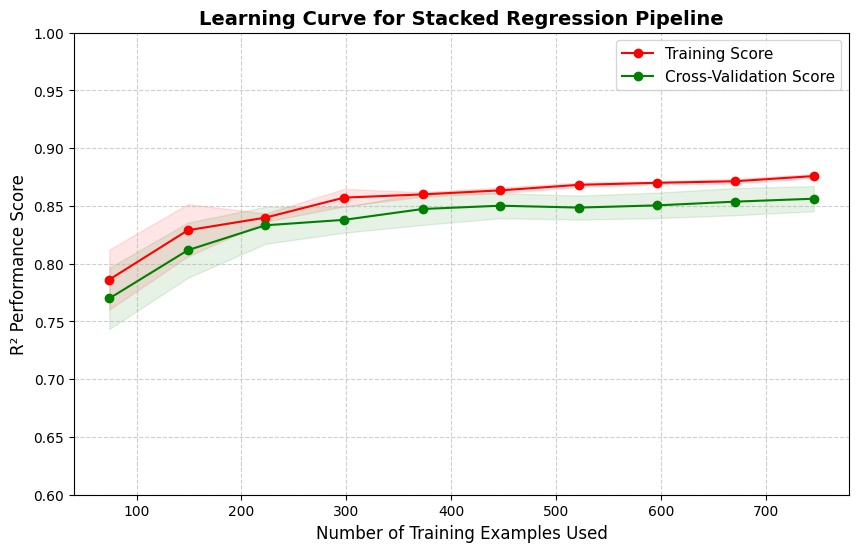

In [ ]:
import numpy as np
import matplotlib.pyplot as plt




# 2. Calculate the learning curve data
# train_sizes dictates the fractions of the training set to use (e.g., 10% up to 100%)
train_sizes, train_scores, validation_scores = learning_curve(
    estimator=pipeline,
    X=x_train,
    y=y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,                  # 5-fold cross-validation at each data size step
    scoring='r2',          # Evaluate using the R² score
    n_jobs=-1
)

# 3. Calculate the mean and standard deviation across the CV folds
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
validation_mean = np.mean(validation_scores, axis=1)
validation_std = np.std(validation_scores, axis=1)

# 4. Generate the plot
plt.figure(figsize=(10, 6))

# Plot training scores
plt.plot(train_sizes, train_mean, 'o-', color="r", label="Training Score")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color="r")

# Plot validation scores
plt.plot(train_sizes, validation_mean, 'o-', color="g", label="Cross-Validation Score")
plt.fill_between(train_sizes, validation_mean - validation_std, validation_mean + validation_std, alpha=0.1, color="g")

# Formatting elements
plt.title("Learning Curve for Stacked Regression Pipeline", fontsize=14, fontweight='bold')

plt.xlabel("Number of Training Examples Used", fontsize=12)
plt.ylabel("R² Performance Score", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc="best", fontsize=11)
plt.ylim(0.6, 1) # Caps the Y-axis logically for R² interpretation
plt.show()

##KNN BR LassoCV Ensesmble

cross validation using LassoCV - affectively adds some devience into the traing fit to reduce deviance in the rest fit https://www.youtube.com/watch?v=Q81RR3yKn30&t=85s

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn import linear_model
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import StackingRegressor
from sklearn.model_selection import GridSearchCV

base_learners = [
    ('lr', linear_model.BayesianRidge()),
    ('knn', KNeighborsRegressor(weights='uniform',n_neighbors=12, algorithm='ball_tree', leaf_size=20))
]

stacking_ensemble = StackingRegressor(
    estimators=base_learners,
    final_estimator=LassoCV(),
    cv = 2,

)

pipeline = Pipeline([
  ('scaler', StandardScaler()),
  ('stack', stacking_ensemble)
])


pipeline.fit(x_train, y_train)
y_train_pred = pipeline.predict(x_train)
y_test_pred = pipeline.predict(x_test)

# 6. Output the results
#print(f"Best Parameters: {grid_search.best_params_}")
#print(f"Best CV R² Score: {grid_search.best_score_:.4f}")
#print(f"Test Set R² Score: {grid_search.score(x_test, y_test):.4f}")

###Assesing the model
measure the training score training R2 - test R2

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
train_score = pipeline.score(x_train, y_train)
train_MSE = mean_squared_error(y_train, y_train_pred)
test_MSE = mean_squared_error(y_test, y_test_pred)
# 2. Calculate the score on the test data
test_score = pipeline.score(x_test, y_test)

print(f"Training R² Score: {train_score:.4f}")
print(f"Test R² Score:     {test_score:.4f}")

# 3. Evaluate the gap
gap = train_score - test_score
print(f"Performance Gap:   {gap:.4f}")

bkl_results = pd.DataFrame(['Baysian Ridge + KNN', 'LassoCV', train_score, test_score, gap, train_MSE, test_MSE]).transpose()
bkl_results.columns = ['Base learners', 'final estimator', 'Training R2', 'testing R2', 'performance gap', 'test MSE', 'train MSE']
bkl_results

Training R² Score: 0.8796
Test R² Score:     0.8481
Performance Gap:   0.0315


,Base learners,final estimator,Training R2,testing R2,performance gap,test MSE,train MSE
0,Baysian Ridge + KNN,LassoCV,0.879589,0.848097,0.031492,0.530642,0.627756


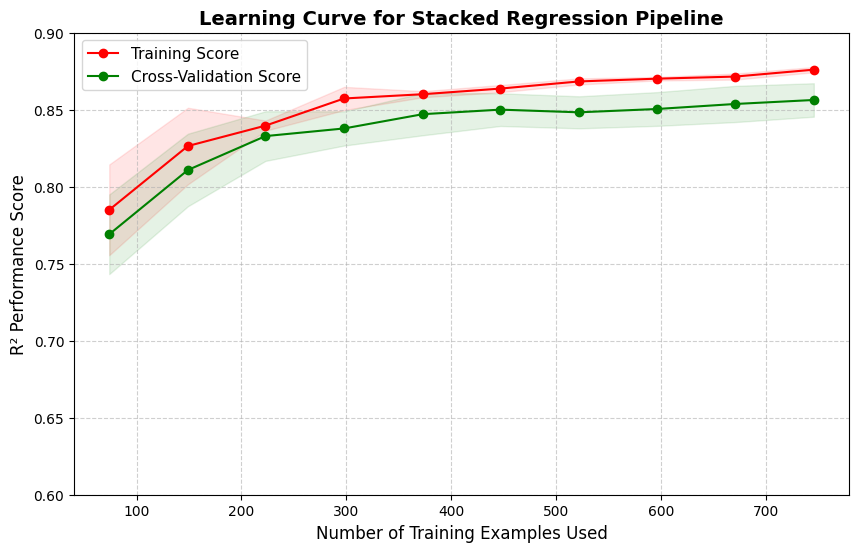

In [ ]:
import numpy as np
import matplotlib.pyplot as plt




# 2. Calculate the learning curve data
# train_sizes dictates the fractions of the training set to use (e.g., 10% up to 100%)
train_sizes, train_scores, validation_scores = learning_curve(
    estimator=pipeline,
    X=x_train,
    y=y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,                  # 5-fold cross-validation at each data size step
    scoring='r2',          # Evaluate using the R² score
    n_jobs=-1
)

# 3. Calculate the mean and standard deviation across the CV folds
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
validation_mean = np.mean(validation_scores, axis=1)
validation_std = np.std(validation_scores, axis=1)

# 4. Generate the plot
plt.figure(figsize=(10, 6))

# Plot training scores
plt.plot(train_sizes, train_mean, 'o-', color="r", label="Training Score")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color="r")

# Plot validation scores
plt.plot(train_sizes, validation_mean, 'o-', color="g", label="Cross-Validation Score")
plt.fill_between(train_sizes, validation_mean - validation_std, validation_mean + validation_std, alpha=0.1, color="g")

# Formatting elements
plt.title("Learning Curve for Stacked Regression Pipeline", fontsize=14, fontweight='bold')

plt.xlabel("Number of Training Examples Used", fontsize=12)
plt.ylabel("R² Performance Score", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc="best", fontsize=11)
plt.ylim(0.6, 0.9) # Caps the Y-axis logically for R² interpretation
plt.show()

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.linear_model import RidgeCV
from sklearn import linear_model
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import StackingRegressor
from sklearn.model_selection import GridSearchCV

#kernel = 1*RBF(length_scale=[1.0,1.0,1.0,1.0], length_scale_bounds=(1e-2, 1e2))

base_learners = [
    ('gpr', GaussianProcessRegressor(optimizer=None, normalize_y=True,  alpha=1e-3)),
    ('br', linear_model.BayesianRidge()),
    ('knn', KNeighborsRegressor())
]

stacking_ensemble = StackingRegressor(
    estimators=base_learners,
    final_estimator=RidgeCV(),
    cv = 3

)

pipeline = Pipeline([
  ('scaler', StandardScaler()),
  ('stack', stacking_ensemble)
])

param_grid = {

    "stack__gpr__kernel": [
        1.0 * RBF(length_scale=[0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5], length_scale_bounds="fixed"),
        1.0 * RBF(length_scale=[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], length_scale_bounds="fixed"),
        1.0 * RBF(length_scale=[2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0], length_scale_bounds="fixed"),
        1.0 * RBF(length_scale=[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0], length_scale_bounds="fixed"),
        # You can add specific custom weighting if you suspect a feature is highly sensitive:
        1.0 * RBF(length_scale=[0.5, 2.0, 1.0, 1.0, 2.0, 1.0, 1.0, 1.0], length_scale_bounds="fixed"),
        1.0 * RBF(length_scale=[0.5, 2.0, 2.0, 1.0, 0.5, 2.0, 1.0, 1.0], length_scale_bounds="fixed"),
    ],
    # Tune the KNN model hidden inside the stack step
    'stack__gpr__alpha': [1e-4, 1e-3, 1e-2, 1e0],

    # Tune the weights parameter of the KNN model inside the stack step
    'stack__knn__weights': ['uniform'],
    'stack__knn__n_neighbors': [5, 7, 9, 11, 15,21]


}
grid_gpr = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
)

grid_gpr.fit(x_train, y_train)

try:
    print("Training grid search sequentially... please wait...")
    grid_gpr.fit(x_train, y_train)

    print("\n--- Model Trained Successfully! ---")
    print(f"Best Parameters: {grid_gpr.best_params_}")
    print(f"Best CV R² Score: {grid_gpr.best_score_:.4f}")
    print(f"Test Set R² Score: {grid_gpr.score(x_test, y_test):.4f}")

except Exception as e:
    print("\n--- Execution Failed! Concrete Error Details Below: ---")
    print(repr(e))

pipeline.fit(x_train, y_train)
y_train_pred = pipeline.predict(x_train)
y_test_pred = pipeline.predict(x_test)

Training grid search sequentially... please wait...

--- Model Trained Successfully! ---
Best Parameters: {'stack__gpr__alpha': 0.01, 'stack__gpr__kernel': 1**2 * RBF(length_scale=[3, 3, 3, 3, 3, 3, 3, 3]), 'stack__knn__n_neighbors': 5, 'stack__knn__weights': 'uniform'}
Best CV R² Score: 0.8890
Test Set R² Score: 0.8803


## KNN GPR Ensemble

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.linear_model import RidgeCV
from sklearn import linear_model
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import StackingRegressor
from sklearn.model_selection import GridSearchCV

#kernel = 1*RBF(length_scale=[1.0,1.0,1.0,1.0], length_scale_bounds=(1e-2, 1e2))

base_learners = [
    ('gpr', GaussianProcessRegressor(optimizer=None, normalize_y=True,  alpha=1e-3)),
    ('br', linear_model.BayesianRidge()),
    ('knn', KNeighborsRegressor())
]

stacking_ensemble = StackingRegressor(
    estimators=base_learners,
    final_estimator=RidgeCV(),
    cv = 3

)

pipeline = Pipeline([
  ('scaler', StandardScaler()),
  ('stack', stacking_ensemble)
])

param_grid = {

    "stack__gpr__kernel": [
        1.0 * RBF(length_scale=[0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5], length_scale_bounds="fixed"),
        1.0 * RBF(length_scale=[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], length_scale_bounds="fixed"),
        1.0 * RBF(length_scale=[2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0], length_scale_bounds="fixed"),
        1.0 * RBF(length_scale=[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0], length_scale_bounds="fixed"),
        # You can add specific custom weighting if you suspect a feature is highly sensitive:
        1.0 * RBF(length_scale=[0.5, 2.0, 1.0, 1.0, 2.0, 1.0, 1.0], length_scale_bounds="fixed"),
        1.0 * RBF(length_scale=[0.5, 2.0, 2.0, 1.0, 0.5, 2.0, 1.0], length_scale_bounds="fixed"),
    ],
    # Tune the KNN model hidden inside the stack step
    'stack__gpr__alpha': [1e-4, 1e-3, 1e-2, 1e0],

    # Tune the weights parameter of the KNN model inside the stack step
    'stack__knn__weights': ['uniform'],
    'stack__knn__n_neighbors': [5, 7, 9, 11, 15,21]


}
grid_gpr = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
)

grid_gpr.fit(x_train, y_train)

try:
    print("Training grid search sequentially... please wait...")
    grid_gpr.fit(x_train, y_train)

    print("\n--- Model Trained Successfully! ---")
    print(f"Best Parameters: {grid_gpr.best_params_}")
    print(f"Best CV R² Score: {grid_gpr.best_score_:.4f}")
    print(f"Test Set R² Score: {grid_gpr.score(x_test, y_test):.4f}")

except Exception as e:
    print("\n--- Execution Failed! Concrete Error Details Below: ---")
    print(repr(e))

pipeline.fit(x_train, y_train)
y_train_pred = pipeline.predict(x_train)
y_test_pred = pipeline.predict(x_test)

ValueError: 
All the 720 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
720 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/pipeline.py", line 662, in fit
    self._final_estimator.fit(Xt, y, **last_step_params["fit"])
    ~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
train_score = pipeline.score(x_train, y_train)
train_MSE = mean_squared_error(y_train, y_train_pred)
test_MSE = mean_squared_error(y_test, y_test_pred)
# 2. Calculate the score on the test data
test_score = pipeline.score(x_test, y_test)

print(f"Training R² Score: {train_score:.4f}")
print(f"Test R² Score:     {test_score:.4f}")

# 3. Evaluate the gap
gap = train_score - test_score
print(f"Performance Gap:   {gap:.4f}")

gpr_results = pd.DataFrame(['GPR + KNN', 'RidgeCV', train_score, test_score, gap, train_MSE, test_MSE]).transpose()
gpr_results.columns = ['Base learners', 'final estimator', 'Training R2', 'testing R2', 'performance gap', 'test MSE', 'train MSE']
gpr_results

In [ ]:
import numpy as np
import matplotlib.pyplot as plt




# 2. Calculate the learning curve data
# train_sizes dictates the fractions of the training set to use (e.g., 10% up to 100%)
gpr_train_sizes, gpr_train_scores, gpr_validation_scores = learning_curve(
    estimator=pipeline,
    X=x_train,
    y=y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,                  # 5-fold cross-validation at each data size step
    scoring='r2',          # Evaluate using the R² score
    n_jobs=-1
)

# 3. Calculate the mean and standard deviation across the CV folds
gpr_train_mean = np.mean(train_scores, axis=1)
gpr_train_std = np.std(train_scores, axis=1)
gpr_validation_mean = np.mean(validation_scores, axis=1)
gpr_validation_std = np.std(validation_scores, axis=1)

# 4. Generate the plot
plt.figure(figsize=(10, 6))

# Plot training scores
plt.plot(train_sizes, train_mean, 'o-', color="r", label="Training Score")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color="r")

# Plot validation scores
plt.plot(train_sizes, validation_mean, 'o-', color="g", label="Cross-Validation Score")
plt.fill_between(gpr_train_sizes, validation_mean - validation_std, validation_mean + validation_std, alpha=0.1, color="g")

# Formatting elements
plt.title("Learning Curve for Stacked Regression Pipeline", fontsize=14, fontweight='bold')

plt.xlabel("Number of Training Examples Used", fontsize=12)
plt.ylabel("R² Performance Score", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc="best", fontsize=11)
plt.ylim(0.6, 1.2) # Caps the Y-axis logically for R² interpretation
plt.show()

##LR GPR BR Ensemble

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import StackingRegressor
from sklearn.model_selection import GridSearchCV

#kernel = 1*RBF(length_scale=[1.0,1.0,1.0,1.0], length_scale_bounds=(1e-2, 1e2))

base_learners = [
    ('gpr', GaussianProcessRegressor(optimizer=None, normalize_y=True,  alpha=1e-3)),
    ('knn', KNeighborsRegressor()),
    ('lr', LinearRegression())
]

stacking_ensemble = StackingRegressor(
    estimators=base_learners,
    final_estimator=RidgeCV(),
    cv = 3

)

pipeline = Pipeline([
  ('scaler', StandardScaler()),
  ('stack', stacking_ensemble)
])

param_grid = {

    "stack__gpr__kernel": [
        1.0 * RBF(length_scale=[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], length_scale_bounds=(1e-2, 1e5)),

    ],
    # Tune the KNN model hidden inside the stack step
    'stack__gpr__alpha': [1e-4, 1e-2, 1e0],

    # Tune the weights parameter of the KNN model inside the stack step
    'stack__knn__weights': ['uniform'],
    'stack__knn__n_neighbors': [3,5,9,11,15,21]


}
grid_gpr = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
)


try:
    print("Training grid search sequentially... please wait...")
    grid_gpr.fit(x_train, y_train)

    print("\n--- Model Trained Successfully! ---")
    print(f"Best Parameters: {grid_gpr.best_params_}")
    print(f"Best CV R² Score: {grid_gpr.best_score_:.4f}")
    print(f"Test Set R² Score: {grid_gpr.score(x_test, y_test):.4f}")

except Exception as e:
    print("\n--- Execution Failed! Concrete Error Details Below: ---")
    print(repr(e))
pipeline.fit(x_train, y_train)
y_train_pred = pipeline.predict(x_train)
y_test_pred = pipeline.predict(x_test)

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
train_score = pipeline.score(x_train, y_train)
train_MSE = mean_squared_error(y_train, y_train_pred)
test_MSE = mean_squared_error(y_test, y_test_pred)
# 2. Calculate the score on the test data
test_score = pipeline.score(x_test, y_test)

print(f"Training R² Score: {train_score:.4f}")
print(f"Test R² Score:     {test_score:.4f}")

# 3. Evaluate the gap
gap = train_score - test_score
print(f"Performance Gap:   {gap:.4f}")

lgb_results = pd.DataFrame(['LR + GPR + KNN', 'RidgeCV', train_score, test_score, gap, train_MSE, test_MSE]).transpose()
lgb_results.columns = ['Base learners', 'final estimator', 'Training R2', 'testing R2', 'performance gap', 'test MSE', 'train MSE']
lgb_results

In [ ]:
import numpy as np
import matplotlib.pyplot as plt




# 2. Calculate the learning curve data
# train_sizes dictates the fractions of the training set to use (e.g., 10% up to 100%)
gpr_train_sizes, gpr_train_scores, gpr_validation_scores = learning_curve(
    estimator=pipeline,
    X=x_train,
    y=y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,                  # 5-fold cross-validation at each data size step
    scoring='r2',          # Evaluate using the R² score
    n_jobs=-1
)

# 3. Calculate the mean and standard deviation across the CV folds
gpr_train_mean = np.mean(gpr_train_scores, axis=1)
gpr_train_std = np.std(gpr_train_scores, axis=1)
gpr_validation_mean = np.mean(gpr_validation_scores, axis=1)
gpr_validation_std = np.std(gpr_validation_scores, axis=1)

# 4. Generate the plot
plt.figure(figsize=(10, 6))

# Plot training scores
plt.plot(gpr_train_sizes, gpr_train_mean, 'o-', color="r", label="Training Score")
plt.fill_between(gpr_train_sizes, gpr_train_mean - gpr_train_std, gpr_train_mean + gpr_train_std, alpha=0.1, color="r")

# Plot validation scores
plt.plot(gpr_train_sizes, gpr_validation_mean, 'o-', color="g", label="Cross-Validation Score")
plt.fill_between(gpr_train_sizes, gpr_validation_mean - gpr_validation_std, gpr_validation_mean + gpr_validation_std, alpha=0.1, color="g")

# Formatting elements
plt.title("Learning Curve for Stacked Regression Pipeline", fontsize=14, fontweight='bold')

plt.xlabel("Number of Training Examples Used", fontsize=12)
plt.ylabel("R² Performance Score", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc="best", fontsize=11)
plt.ylim(0.6, 1.2) # Caps the Y-axis logically for R² interpretation
plt.show()

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import StackingRegressor
from sklearn.model_selection import GridSearchCV

#kernel = 1*RBF(length_scale=[1.0,1.0,1.0,1.0], length_scale_bounds=(1e-2, 1e2))

base_learners = [
    ('gpr', GaussianProcessRegressor(optimizer=None, normalize_y=True,  alpha=1e-3)),
    ('knn', KNeighborsRegressor())
]

stacking_ensemble = StackingRegressor(
    estimators=base_learners,
    final_estimator=RidgeCV(),
    cv = 3

)

pipeline = Pipeline([
  ('scaler', StandardScaler()),
  ('stack', stacking_ensemble)
])

param_grid = {

    "stack__gpr__kernel": [
        1.0 * RBF(length_scale=[0.5, 0.5, 0.5, 0.5], length_scale_bounds="fixed"),
        1.0 * RBF(length_scale=[1.0, 1.0, 1.0, 1.0], length_scale_bounds="fixed"),
        1.0 * RBF(length_scale=[2.0, 2.0, 2.0, 2.0], length_scale_bounds="fixed"),
        # You can add specific custom weighting if you suspect a feature is highly sensitive:
        1.0 * RBF(length_scale=[0.5, 2.0, 1.0, 1.0], length_scale_bounds="fixed"),
    ],
    # Tune the KNN model hidden inside the stack step
    'stack__gpr__alpha': [1e-4, 1e-2, 1e0],

    # Tune the weights parameter of the KNN model inside the stack step
    'stack__knn__weights': ['uniform'],
    'stack__knn__n_neighbors': [9,11,15,21]


}
grid_gpr = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
)

grid_gpr.fit(x_train, y_train)

try:
    print("Training grid search sequentially... please wait...")
    grid_gpr.fit(x_train, y_train)

    print("\n--- Model Trained Successfully! ---")
    print(f"Best Parameters: {grid_gpr.best_params_}")
    print(f"Best CV R² Score: {grid_gpr.best_score_:.4f}")
    print(f"Test Set R² Score: {grid_gpr.score(x_test, y_test):.4f}")

except Exception as e:
    print("\n--- Execution Failed! Concrete Error Details Below: ---")
    print(repr(e))
y_train_pred = pipeline.predict(x_train)
y_test_pred = pipeline.predict(x_test)


In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
train_score = pipeline.score(x_train, y_train)
train_MSE = mean_squared_error(y_train, y_train_pred)
test_MSE = mean_squared_error(y_test, y_test_pred)
# 2. Calculate the score on the test data
test_score = pipeline.score(x_test, y_test)

print(f"Training R² Score: {train_score:.4f}")
print(f"Test R² Score:     {test_score:.4f}")

# 3. Evaluate the gap
gap = train_score - test_score
print(f"Performance Gap:   {gap:.4f}")

gkg_results = pd.DataFrame(['GPR + KNN', 'RidgeCV', train_score, test_score, gap, train_MSE, test_MSE]).transpose()
gkg_results.columns = ['Base learners', 'final estimator', 'Training R2', 'testing R2', 'performance gap', 'test MSE', 'train MSE']
gkg_results

##GPR+BR+KNN Ensemble

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.linear_model import RidgeCV
from sklearn import linear_model
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import StackingRegressor
from sklearn.model_selection import GridSearchCV

kernel = 1.0 * RBF(length_scale=[2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0], length_scale_bounds="fixed")
base_learners = [
    ('gpr', GaussianProcessRegressor(optimizer=None, normalize_y=True,  alpha=0.001, kernel=kernel)),
    ('lr', linear_model.BayesianRidge()),
    ('knn', KNeighborsRegressor(n_neighbors=9, weights='uniform'))
]

stacking_ensemble = StackingRegressor(
    estimators=base_learners,
    final_estimator=RidgeCV(),
    cv = 4

)

pipeline = Pipeline([
  ('scaler', StandardScaler()),
  ('stack', stacking_ensemble)
])




pipeline.fit(x_train, y_train)
y_train_pred = pipeline.predict(x_train)
y_test_pred = pipeline.predict(x_test)

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
train_score = pipeline.score(x_train, y_train)
train_MSE = mean_squared_error(y_train, y_train_pred)
test_MSE = mean_squared_error(y_test, y_test_pred)
# 2. Calculate the score on the test data
test_score = pipeline.score(x_test, y_test)

print(f"Training R² Score: {train_score:.4f}")
print(f"Test R² Score:     {test_score:.4f}")

# 3. Evaluate the gap
gap = train_score - test_score
print(f"Performance Gap:   {gap:.4f}")

gbk_results = pd.DataFrame(['GPR + KNN + BR', 'RidgeCV', train_score, test_score, gap, train_MSE, test_MSE]).transpose()
gbk_results.columns = ['Base learners', 'final estimator', 'Training R2', 'testing R2', 'performance gap', 'test MSE', 'train MSE']
gbk_results

##LR GPR BR ensemble with LassoCV

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.linear_model import RidgeCV
from sklearn import linear_model
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import StackingRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score

kernel = 1.0 * RBF(length_scale=[2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0], length_scale_bounds="fixed")
base_learners = [
    ('gpr', GaussianProcessRegressor(optimizer=None, normalize_y=True,  alpha=0.01, kernel=kernel)),
    ('lr', linear_model.BayesianRidge()),
    ('knn', KNeighborsRegressor(n_neighbors=11, weights='uniform'))
]

stacking_ensemble = StackingRegressor(
    estimators=base_learners,
    final_estimator=LassoCV(),
    cv = 2

)

pipeline = Pipeline([
  ('scaler', StandardScaler()),
  ('stack', stacking_ensemble)
])




pipeline.fit(x_train, y_train)
y_train_pred = pipeline.predict(x_train)
y_test_pred = pipeline.predict(x_test)

train_score = pipeline.score(x_train, y_train)
train_MSE = mean_squared_error(y_train, y_train_pred)
test_MSE = mean_squared_error(y_test, y_test_pred)
# 2. Calculate the score on the test data
test_score = pipeline.score(x_test, y_test)

print(f"Training R² Score: {train_score:.4f}")
print(f"Test R² Score:     {test_score:.4f}")

# 3. Evaluate the gap
gap = train_score - test_score
print(f"Performance Gap:   {gap:.4f}")

gbkl_results = pd.DataFrame(['GPR + KNN + BR', 'LassoCV', train_score, test_score, gap, train_MSE, test_MSE]).transpose()
gbkl_results.columns = ['Base learners', 'final estimator', 'Training R2', 'testing R2', 'performance gap', 'test MSE', 'train MSE']
gbkl_results

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import RidgeCV
from sklearn import svm
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import StackingRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.feature_selection import VarianceThreshold




'''base_learners = [
    ('rf', RandomForestRegressor (max_depth=None, random_state=100)),
    ('svm', svm.SVR()),
    #('knn', KNeighborsRegressor(n_neighbors=11, weights='uniform'))
]'''

base_learners = [
    ('svm', svm.SVR()),
    #('knn', KNeighborsRegressor(n_neighbors=11, weights='uniform'))
]

stacking_ensemble = StackingRegressor(
    estimators=base_learners,
    #final_estimator=LassoCV(),
    cv = 4

)

pipeline = Pipeline([
  ('scaler', StandardScaler()),
  ('stack', stacking_ensemble)
])



sel = VarianceThreshold(threshold=(.8 * (1 - .8)))
pipeline.fit(x_train, y_train)
y_train_pred = pipeline.predict(x_train)
y_test_pred = pipeline.predict(x_test)

svlr_train_score = pipeline.score(x_train, y_train)
svlr_train_MSE = mean_squared_error(y_train, y_train_pred)
svlr_test_MSE = mean_squared_error(y_test, y_test_pred)
# 2. Calculate the score on the test data
svlr_test_score = pipeline.score(x_test, y_test)

print(f"Training R² Score: {svlr_train_score:.4f}")
print(f"Test R² Score:     {svlr_test_score:.4f}")

# 3. Evaluate the gap
svlr_gap = svlr_train_score - svlr_test_score
print(f"Performance Gap:   {gap:.4f}")

svlr_results = pd.DataFrame(['SVM+RF', 'LassoCV', svlr_train_score, svlr_test_score, svlr_gap, svlr_test_MSE, svlr_train_MSE]).transpose()
svlr_results.columns = ['Base learners', 'final estimator', 'Training R2', 'testing R2', 'performance gap', 'test MSE', 'train MSE']
svlr_results

#test for benzoic acid